In [2]:
import pandas as pd
import numpy as np

spacex_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv"

df = pd.read_csv(spacex_url)
df["Date"] = pd.to_datetime(df["Date"])

print(f"Loaded {len(df)} SpaceX Falcon 9 missions across {df['Serial'].nunique()} unique booster cores!")
df[["FlightNumber", "Date", "Serial", "Flights", "LaunchSite", "PayloadMass", "Orbit", "Outcome"]].tail(10)

Loaded 90 SpaceX Falcon 9 missions across 53 unique booster cores!


,FlightNumber,Date,Serial,Flights,LaunchSite,PayloadMass,Orbit,Outcome
80,81,2020-06-13,B1059,3,CCAFS SLC 40,15400.000000,VLEO,True ASDS
81,82,2020-06-30,B1060,1,CCAFS SLC 40,3880.000000,MEO,True ASDS
82,83,2020-07-20,B1058,2,CCAFS SLC 40,6104.959412,GEO,True ASDS
83,84,2020-08-18,B1049,6,CCAFS SLC 40,15400.000000,VLEO,True ASDS
84,85,2020-08-30,B1059,4,CCAFS SLC 40,1600.000000,SSO,True RTLS
85,86,2020-09-03,B1060,2,KSC LC 39A,15400.000000,VLEO,True ASDS
86,87,2020-10-06,B1058,3,KSC LC 39A,15400.000000,VLEO,True ASDS
87,88,2020-10-18,B1051,6,KSC LC 39A,15400.000000,VLEO,True ASDS
88,89,2020-10-24,B1060,3,CCAFS SLC 40,15400.000000,VLEO,True ASDS
89,90,2020-11-05,B1062,1,CCAFS SLC 40,3681.000000,MEO,True ASDS


In [3]:
df = df.sort_values(["Serial", "Date"]).reset_index(drop=True)
df["booster_turnaround_days"] = df.groupby("Serial")["Date"].diff().dt.days

reused_flights = df[df["booster_turnaround_days"].notna()].copy()

print(f"Total Reflown Booster Missions Analyzed: {len(reused_flights)}")
print(f"Fleet Median Booster Turnaround: {round(reused_flights['booster_turnaround_days'].median(), 1)} days")
print(f"Fastest Booster Turnaround Record in Dataset: {int(reused_flights['booster_turnaround_days'].min())} days")

reused_flights[["Serial", "Flights", "Date", "LaunchSite", "Orbit", "booster_turnaround_days"]].sort_values("booster_turnaround_days").head(10)

Total Reflown Booster Missions Analyzed: 37
Fleet Median Booster Turnaround: 128.0 days
Fastest Booster Turnaround Record in Dataset: 51 days


,Serial,Flights,Date,LaunchSite,Orbit,booster_turnaround_days
88,B1060,3,2020-10-24,CCAFS SLC 40,VLEO,51.0
80,B1058,2,2020-07-20,CCAFS SLC 40,GEO,51.0
78,B1056,4,2020-02-17,CCAFS SLC 40,VLEO,62.0
87,B1060,2,2020-09-03,KSC LC 39A,VLEO,65.0
50,B1045,2,2018-06-29,CCAFS SLC 40,ISS,72.0
59,B1048,2,2018-10-08,VAFB SLC 4E,SSO,75.0
67,B1049,6,2020-08-18,CCAFS SLC 40,VLEO,75.0
81,B1058,3,2020-10-06,KSC LC 39A,VLEO,78.0
85,B1059,4,2020-08-30,CCAFS SLC 40,SSO,78.0
76,B1056,2,2019-07-25,CCAFS SLC 40,ISS,82.0


In [4]:
block_benchmark = reused_flights.groupby("Block")["booster_turnaround_days"].agg(
    reflown_missions="count",
    median_turnaround_days="median",
    mean_turnaround_days="mean",
    fastest_turnaround_days="min"
).round(1)

df["landing_success"] = df["Outcome"].str.startswith("True")

pad_benchmark = df.groupby("LaunchSite").agg(
    total_launches=("FlightNumber", "count"),
    reused_booster_launches=("Reused", "sum"),
    total_payload_kg=("PayloadMass", "sum"),
    avg_payload_kg=("PayloadMass", "mean"),
    landing_success_rate_pct=("landing_success", lambda x: round(x.mean() * 100, 1))
).round(1)

print("--- FALCON 9 BLOCK GENERATION TURNAROUND BENCHMARK ---")
display(block_benchmark)

print("\n--- LAUNCH COMPLEX (PAD) THROUGHPUT & RECOVERY BENCHMARK ---")
display(pad_benchmark)

--- FALCON 9 BLOCK GENERATION TURNAROUND BENCHMARK ---


,reflown_missions,median_turnaround_days,mean_turnaround_days,fastest_turnaround_days
Block,,,,
2.0,1,356.0,356.0,356.0
3.0,5,195.0,209.0,160.0
4.0,4,201.5,186.2,72.0
5.0,27,102.0,137.3,51.0



--- LAUNCH COMPLEX (PAD) THROUGHPUT & RECOVERY BENCHMARK ---


,total_launches,reused_booster_launches,total_payload_kg,avg_payload_kg,landing_success_rate_pct
LaunchSite,,,,,
CCAFS SLC 40,55,21,305151.4,5548.2,60.0
KSC LC 39A,22,10,167341.9,7606.5,77.3
VAFB SLC 4E,13,6,76953.0,5919.5,76.9


,missions,median_turnaround_days,mean_turnaround_days,min_turnaround_days
Flights,,,,
2,19,123.0,154.8,51.0
3,8,125.5,139.8,51.0
4,6,156.0,210.5,62.0
5,2,138.5,138.5,128.0
6,2,127.0,127.0,75.0


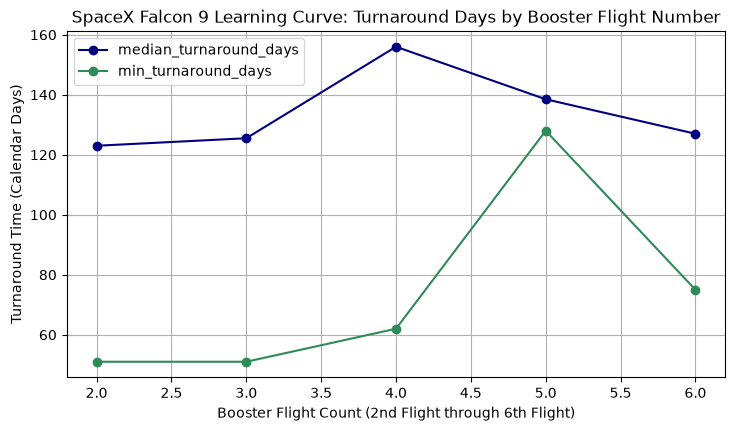

In [5]:
learning_curve = reused_flights.groupby("Flights")["booster_turnaround_days"].agg(
    missions="count",
    median_turnaround_days="median",
    mean_turnaround_days="mean",
    min_turnaround_days="min"
).round(1)

learning_curve[["median_turnaround_days", "min_turnaround_days"]].plot(
    kind="line",
    marker="o",
    color=["navy", "seagreen"],
    title="SpaceX Falcon 9 Learning Curve: Turnaround Days by Booster Flight Number",
    xlabel="Booster Flight Count (2nd Flight through 6th Flight)",
    ylabel="Turnaround Time (Calendar Days)",
    grid=True,
    figsize=(8.5, 4.5)
)

learning_curve

In [6]:
reused_flights["mission_profile"] = np.where(
    reused_flights["Orbit"] == "VLEO",
    "Internal Starlink (VLEO)",
    "External Customer / Gov"
)

profile_benchmark = reused_flights.groupby("mission_profile")["booster_turnaround_days"].agg(
    reflown_flights="count",
    median_turnaround_days="median",
    mean_turnaround_days="mean",
    fastest_turnaround_days="min"
).round(1)

df = df.sort_values(["LaunchSite", "Date"]).reset_index(drop=True)
df["pad_turnaround_days"] = df.groupby("LaunchSite")["Date"].diff().dt.days

pad_cadence = df.groupby("LaunchSite")["pad_turnaround_days"].agg(
    median_pad_reset_days="median",
    fastest_pad_reset_days="min"
).round(1)

print("--- STARLINK (VLEO) VS EXTERNAL CUSTOMER BOOSTER TURNAROUND ---")
display(profile_benchmark)

print("\n--- LAUNCH PAD RESET CADENCE (DAYS BETWEEN LAUNCHES AT SAME PAD) ---")
display(pad_cadence)

df.to_csv("spacex_falcon9_turnaround_clean.csv", index=False)

--- STARLINK (VLEO) VS EXTERNAL CUSTOMER BOOSTER TURNAROUND ---


,reflown_flights,median_turnaround_days,mean_turnaround_days,fastest_turnaround_days
mission_profile,,,,
External Customer / Gov,23,145.0,169.3,51.0
Internal Starlink (VLEO),14,113.0,140.0,51.0



--- LAUNCH PAD RESET CADENCE (DAYS BETWEEN LAUNCHES AT SAME PAD) ---


,median_pad_reset_days,fastest_pad_reset_days
LaunchSite,,
CCAFS SLC 40,27.5,9.0
KSC LC 39A,33.0,12.0
VAFB SLC 4E,86.0,39.0
